<a href="https://colab.research.google.com/github/kavyasree4494/OIBSIP/blob/main/OIBSIP_DataAnalytics_L2_Customer_Segmentation_Analysis_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
csv_path = '/content/global_ecommerce_sales.csv'
df = pd.read_csv(csv_path)
print("--- Dataset successfully loaded! ---")
print("\n--- Dataset Info ---")
display(df.info())
print("First 5 Rows")
display(df.head())
print(" Missing Values Count")
missing_counts = df.isnull().sum()
display(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values found.")
num_cols = df.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Filled missing values in '{col}' with median: {median_val}")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna('Unknown')
        print(f"Filled missing values in '{col}' with 'Unknown'")
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()
display(df.head())

--- Dataset successfully loaded! ---

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   object 
 1   Order_Date        2000 non-null   object 
 2   Customer_Name     2000 non-null   object 
 3   Customer_Segment  2000 non-null   object 
 4   Country           2000 non-null   object 
 5   Region            2000 non-null   object 
 6   Product_Category  2000 non-null   object 
 7   Product_Name      2000 non-null   object 
 8   Quantity          2000 non-null   int64  
 9   Unit_Price        2000 non-null   float64
 10  Discount_Percent  2000 non-null   int64  
 11  Total_Sales       2000 non-null   float64
 12  Shipping_Cost     2000 non-null   float64
 13  Profit            2000 non-null   float64
 14  Payment_Method    2000 non-null   object 
dtypes: float64(4), int64(2), objec

None

First 5 Rows


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,02-01-2023,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,02-01-2023,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,03-01-2023,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,03-01-2023,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,05-01-2023,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


 Missing Values Count


'No missing values found.'

,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,02-01-2023,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,02-01-2023,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,03-01-2023,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,03-01-2023,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,05-01-2023,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


In [ ]:
import pandas as pd
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
customer_stats = df.groupby('Customer_Name').agg(
    total_revenue=('Total_Sales', 'sum'),
    purchase_count=('Order_ID', 'nunique'),
    avg_purchase_value=('Total_Sales', 'mean')
).reset_index()
overall_avg_purchase_value = df['Total_Sales'].mean()
overall_purchase_frequency = customer_stats['purchase_count'].mean()
customer_stats['Estimated_CLV'] = customer_stats['total_revenue']
overall_clv = customer_stats['Estimated_CLV'].mean()
print("Overall E-commerce Metrics")
print(f"Overall Average Purchase Value: ${overall_avg_purchase_value:.2f}")
print(f"Overall Average Purchase Frequency (per customer): {overall_purchase_frequency:.2f} times")
print(f"Overall Average Customer Lifetime Value (total sales per customer): ${overall_clv:.2f}")
print("Customer Level Details (Top 10 Customers by Value)")
display(customer_stats.sort_values(by='Estimated_CLV', ascending=False).head(10))

Overall E-commerce Metrics
Overall Average Purchase Value: $242.28
Overall Average Purchase Frequency (per customer): 1.30 times
Overall Average Customer Lifetime Value (total sales per customer): $315.88
Customer Level Details (Top 10 Customers by Value)


,Customer_Name,total_revenue,purchase_count,avg_purchase_value,Estimated_CLV
1195,Priya Jackson,3836.46,2,1918.230000,3836.46
455,Hanna Jones,3813.98,1,3813.980000,3813.98
1315,Sarah Chen,3184.56,2,1592.280000,3184.56
800,Li Laurent,3007.62,1,3007.620000,3007.62
1024,Nadia Wang,2958.97,3,986.323333,2958.97
1205,Priya Oliveira,2901.11,1,2901.110000,2901.11
418,Felix Thompson,2835.36,1,2835.360000,2835.36
857,Linda Weber,2762.40,1,2762.400000,2762.40
737,Karen Sato,2738.18,2,1369.090000,2738.18
873,Lucas Nilsson,2734.69,2,1367.345000,2734.69


In [ ]:
import pandas as pd
import numpy as np
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
reference_date = df['Order_Date'].max() + pd.Timedelta(days=1)
rfm_df = df.groupby('Customer_Name').agg({
    'Order_Date': lambda x: (reference_date - x.max()).days,
    'Order_ID': 'nunique',
    'Total_Sales': 'sum'
}).reset_index()
rfm_df.rename(columns={
    'Order_Date': 'Recency',
    'Order_ID': 'Frequency',
    'Total_Sales': 'Monetary'
}, inplace=True)
print("RFM Behavioral Features Summary")
display(rfm_df.describe())
print("Top 5 Customer RFM Profiles")
display(rfm_df.head())


RFM Behavioral Features Summary


,Recency,Frequency,Monetary
count,741.000000,1534.000000,1534.000000
mean,526.334683,1.303781,315.879622
std,319.040684,0.566767,453.225204
min,1.000000,1.000000,2.580000
25%,246.000000,1.000000,57.055000
50%,520.000000,1.000000,151.430000
75%,823.000000,2.000000,391.900000
max,1075.000000,5.000000,3836.460000


Top 5 Customer RFM Profiles


,Customer_Name,Recency,Frequency,Monetary
0,Ahmed Ali,NaN,1,509.12
1,Ahmed Anderson,NaN,1,133.68
2,Ahmed Clark,588.0,2,94.28
3,Ahmed Dubois,11.0,3,105.73
4,Ahmed Garcia,NaN,2,1769.48


In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
rfm_clean = rfm_df.copy()
rfm_clean['Recency'] = rfm_clean['Recency'].fillna(rfm_clean['Recency'].median())
rfm_clean['Frequency'] = rfm_clean['Frequency'].fillna(1)
rfm_clean['Monetary'] = rfm_clean['Monetary'].fillna(rfm_clean['Monetary'].median())
features = ['Recency', 'Frequency', 'Monetary']
X = rfm_clean[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
scaled_features_df = pd.DataFrame(X_scaled, columns=[f'{col}_Scaled' for col in features])
scaled_features_df['Customer_Name'] = rfm_clean['Customer_Name']
print("Original RFM Features Sample")
display(rfm_clean.head())
print("Standardized RFM Features Sample")
display(scaled_features_df.head())
print("Scaled Features Summary (Mean should be ~0 and Std should be ~1)")
display(scaled_features_df[[f'{col}_Scaled' for col in features]].describe())

Original RFM Features Sample


,Customer_Name,Recency,Frequency,Monetary
0,Ahmed Ali,520.0,1,509.12
1,Ahmed Anderson,520.0,1,133.68
2,Ahmed Clark,588.0,2,94.28
3,Ahmed Dubois,11.0,3,105.73
4,Ahmed Garcia,520.0,2,1769.48


Standardized RFM Features Sample


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled,Customer_Name
0,-0.013808,-0.536164,0.426506,Ahmed Ali
1,-0.013808,-0.536164,-0.402138,Ahmed Anderson
2,0.293035,1.228804,-0.489099,Ahmed Clark
3,-2.310613,2.993773,-0.463827,Ahmed Dubois
4,-0.013808,1.228804,3.208282,Ahmed Garcia


Scaled Features Summary (Mean should be ~0 and Std should be ~1)


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
count,1.534000e+03,1.534000e+03,1.534000e+03
mean,-2.478099e-16,-2.315980e-17,-3.010774e-17
std,1.000326e+00,1.000326e+00,1.000326e+00
min,-2.355737e+00,-5.361637e-01,-6.914924e-01
25%,-1.380779e-02,-5.361637e-01,-5.712591e-01
50%,-1.380779e-02,-5.361637e-01,-3.629614e-01
75%,-1.380779e-02,1.228804e+00,1.677867e-01
max,2.490568e+00,6.523709e+00,7.770372e+00


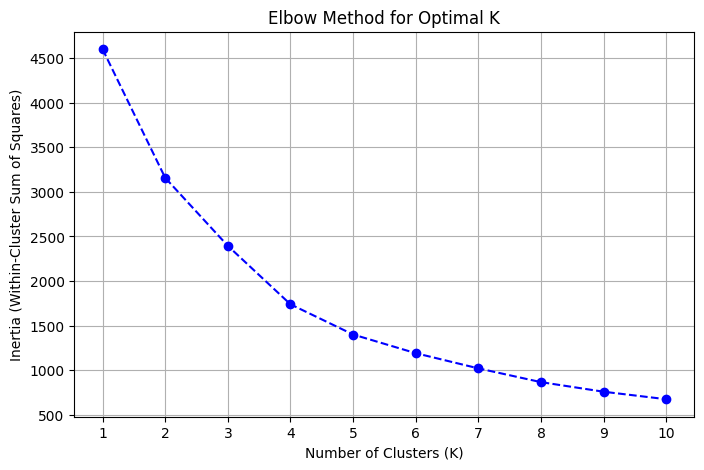

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
inertia = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.xticks(k_range)
plt.show()

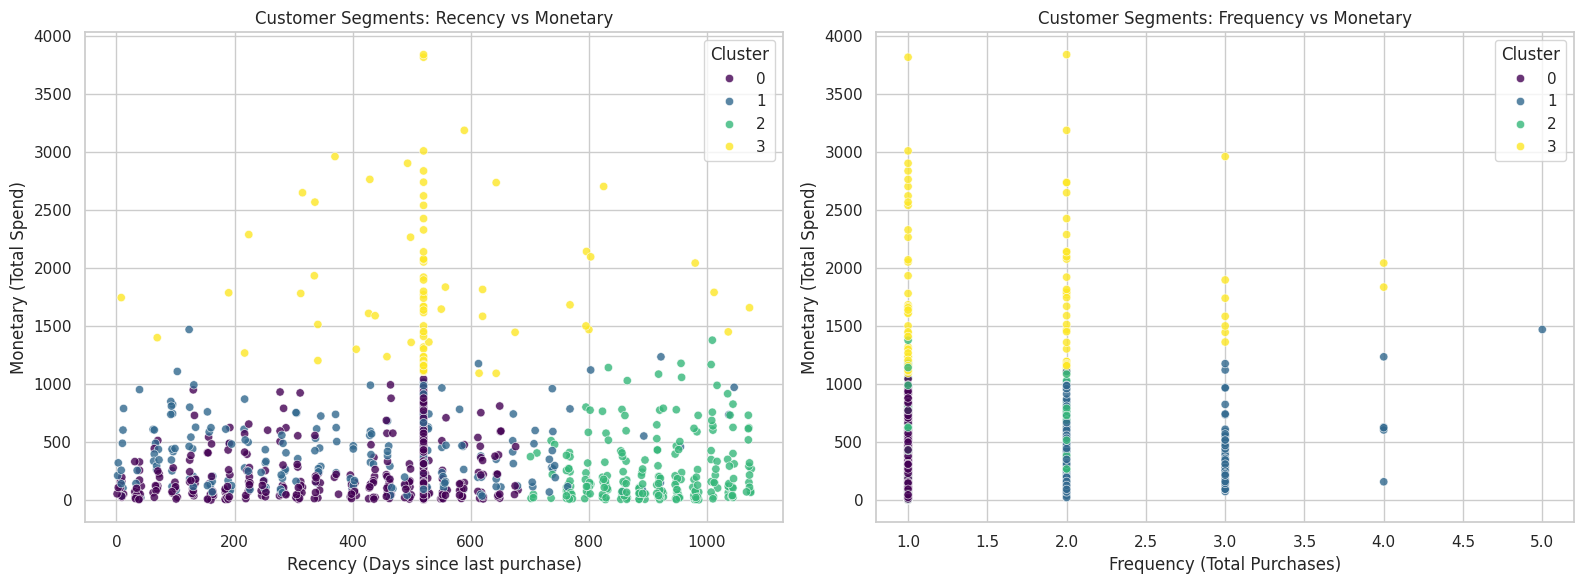

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
rfm_clean['Cluster'] = kmeans.fit_predict(X_scaled)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(
    ax=axes[0],
    data=rfm_clean,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    alpha=0.8,
    edgecolor='w'
)
axes[0].set_title('Customer Segments: Recency vs Monetary')
axes[0].set_xlabel('Recency (Days since last purchase)')
axes[0].set_ylabel('Monetary (Total Spend)')
sns.scatterplot(
    ax=axes[1],
    data=rfm_clean,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    alpha=0.8,
    edgecolor='w'
)
axes[1].set_title('Customer Segments: Frequency vs Monetary')
axes[1].set_xlabel('Frequency (Total Purchases)')
axes[1].set_ylabel('Monetary (Total Spend)')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
cluster_profiles = rfm_clean.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Customer_Name': 'count'
}).rename(columns={'Customer_Name': 'Customer_Count'}).reset_index()
def describe_segment(row):
    if row['Monetary'] > rfm_clean['Monetary'].mean() * 1.5:
        return "High-spending VIPs (High Monetary)"
    elif row['Frequency'] > rfm_clean['Frequency'].mean() * 1.5:
        return "Frequent Buyers (High Frequency)"
    elif row['Recency'] < rfm_clean['Recency'].mean() * 0.5:
        return "New / Recently Active Customers (Low Recency)"
    elif row['Recency'] > rfm_clean['Recency'].mean() * 1.5:
        return "At-risk / Churned Customers (High Recency)"
    else:
        return "Average/Standard Customers"
cluster_profiles['Segment_Description'] = cluster_profiles.apply(describe_segment, axis=1)
print("Cluster Profiles")
display(cluster_profiles)

Cluster Profiles


,Cluster,Recency,Frequency,Monetary,Customer_Count,Segment_Description
0,0,462.385113,1.000000,179.931791,927,Average/Standard Customers
1,1,424.267559,2.210702,359.992207,299,Frequent Buyers (High Frequency)
2,2,906.909910,1.225225,252.208333,222,At-risk / Churned Customers (High Recency)
3,3,529.686047,1.627907,1792.263372,86,High-spending VIPs (High Monetary)


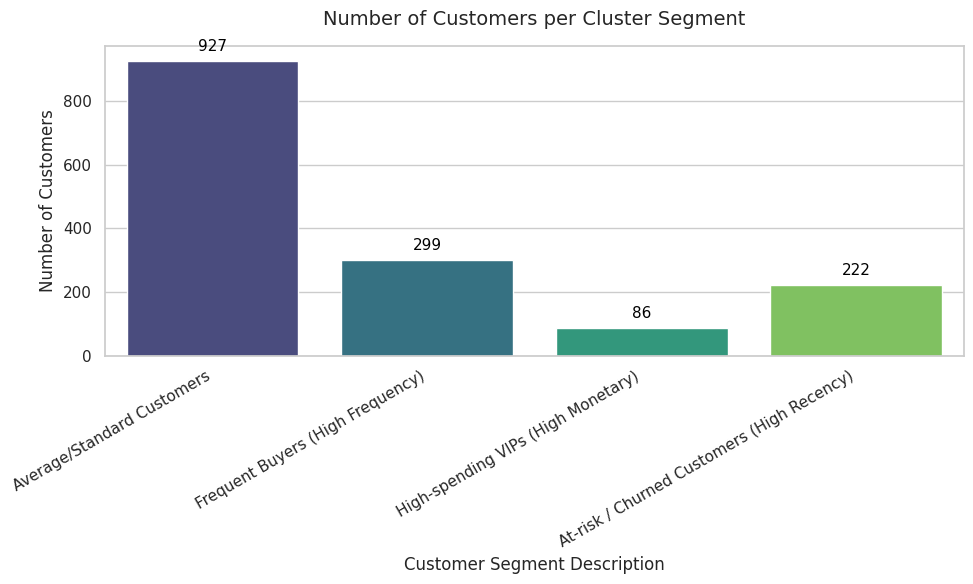

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
cluster_map = dict(zip(cluster_profiles['Cluster'], cluster_profiles['Segment_Description']))
rfm_clean['Segment_Description'] = rfm_clean['Cluster'].map(cluster_map)
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=rfm_clean,
    x='Segment_Description',
    palette='viridis',
    hue='Segment_Description',
    legend=False
)
plt.title('Number of Customers per Cluster Segment', fontsize=14, pad=15)
plt.xlabel('Customer Segment Description', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.xticks(rotation=30, ha='right')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=11, color='black',
                xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### 📊 Strategic Marketing Recommendations per Segment

Based on the RFM profile of each cluster, here are targeted marketing actions designed to maximize retention, loyalty, and lifetime value:

#### 1. **High-spending VIPs (High Monetary)**
* **Profile:** Highest monetary value, moderate purchase frequency, and stable recency.
* **Goal:** Maximize retention and leverage brand advocacy.
* **Recommended Actions:**
  * **Exclusive Loyalty Program:** Invite them to an invite-only VIP loyalty tier featuring early access to new product collections.
  * **Dedicated Support:** Provide priority customer support or a dedicated point of contact to enhance their shopping experience.
  * **Personalized Perks:** Send tailored rewards such as handwritten thank-you notes, brand merchandise, or high-value personalized offers that don't rely heavily on flat discounting.

#### 2. **Frequent Buyers (High Frequency)**
* **Profile:** High purchase frequency, solid monetary contribution, and strong recency.
* **Goal:** Increase average order value (AOV) and expand share of wallet.
* **Recommended Actions:**
  * **Product Bundling:** Present personalized cross-sell and up-sell bundles based on their individual order history.
  * **Subscription Options:** Encourage subscription models for consumable or recurring purchases to secure a steady stream of revenue.
  * **Milestone Rewards:** Offer frequency-based points or milestones that incentivize them to keep buying often.

#### 3. **Average/Standard Customers**
* **Profile:** Moderate spend, low frequency, and average recency. This is the largest segment.
* **Goal:** Cultivate habits and nudge them toward becoming repeat/frequent buyers.
* **Recommended Actions:**
  * **Nurture Campaigns:** Set up automated lifecycle email sequences showcasing popular products and customer testimonials to build trust.
  * **Next-Purchase Incentives:** Provide moderate discounts or free shipping on their second and third orders to establish a purchasing habit.
  * **Low-barrier Referral Rewards:** Offer discounts for both them and a friend to acquire similar prospects at a low cost.

#### 4. **At-risk / Churned Customers (High Recency)**
* **Profile:** Longest time since last purchase, low-to-moderate frequency, and lower spend.
* **Goal:** Re-engagement and churn prevention.
* **Recommended Actions:**
  * **Win-back Campaigns:** Deploy time-sensitive "We miss you" campaigns with strong incentive-driven discounts (e.g., 20% off or a free gift).
  * **Feedback Surveys:** Send short surveys to understand why they haven't purchased recently (e.g., price, shipping speed, or service issues).
  * **Product Highlights:** Re-introduce the brand by showcasing new arrivals or highlighting product improvements since their last visit.